# Robust Rice Leaf Disease Classification

**Ý tưởng:**
1. **Tiền xử lý ảnh:** dùng CLAHE (cân bằng sáng) để giảm ảnh hưởng của bóng râm/ánh sáng không đều.
2. **Trích đặc trưng thủ công:**
   - Màu sắc: histogram màu (không gian HSV) - phân biệt màu đốm bệnh
   - Hình dạng/đường viền: HOG - bắt hình dạng vết bệnh theo hướng cạnh
3. **Tăng cường dữ liệu train bằng OpenCV** (lật ảnh, đổi độ sáng, xoay nhẹ, làm mờ nhẹ) để mô phỏng trước nhiễu của đề bài, giúp model tổng quát hóa tốt hơn.
4. **So sánh nhiều model classical ML** và chọn model tốt nhất theo Macro F1-Score.


## 1. Cấu hình & Setup

In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from skimage.feature import hog

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# ==================== CONFIG ====================
# Đổi TEST_DIR khi chuyển từ Warmup sang Speedup
BASE_DIR = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup"

TRAIN_DIR      = os.path.join(BASE_DIR, "train")
TEST_DIR       = os.path.join(BASE_DIR, "test_warmup")
LABEL_MAP_PATH = os.path.join(BASE_DIR, "label_mapping.json")

FEATURE_IMG_SIZE = (128, 128)   # kích thước resize trước khi trích đặc trưng
VAL_RATIO = 0.15

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)

TRAIN_DIR: /kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train
TEST_DIR : /kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup


## 2. Khám phá dữ liệu (EDA)

Kiểm tra số lượng ảnh mỗi lớp và xem ảnh mẫu.

In [3]:
with open(LABEL_MAP_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)
print("Label mapping từ BTC:", label_mapping)

class_names = sorted(os.listdir(TRAIN_DIR))
print("8 lớp bệnh:", class_names)

Label mapping từ BTC: {'Bacterial Leaf Blight': 0, 'Brown Spot': 1, 'Healthy Rice Leaf': 2, 'Leaf Blast': 3, 'Leaf scald': 4, 'Narrow Brown Leaf Spot': 5, 'Rice Hispa': 6, 'Sheath Blight': 7}
8 lớp bệnh: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Narrow Brown Leaf Spot', 'Rice Hispa', 'Sheath Blight']


In [4]:
class_counts = {}
image_paths, image_labels = [], []

for cls in class_names:
    cls_dir = os.path.join(TRAIN_DIR, cls)
    files = [f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    class_counts[cls] = len(files)
    for f in files:
        image_paths.append(os.path.join(cls_dir, f))
        image_labels.append(cls)

print("Tổng số ảnh train:", len(image_paths))
pd.Series(class_counts).sort_values(ascending=False)

Tổng số ảnh train: 2026


Leaf Blast                360
Sheath Blight             352
Brown Spot                289
Rice Hispa                260
Bacterial Leaf Blight     226
Leaf scald                220
Healthy Rice Leaf         193
Narrow Brown Leaf Spot    126
dtype: int64

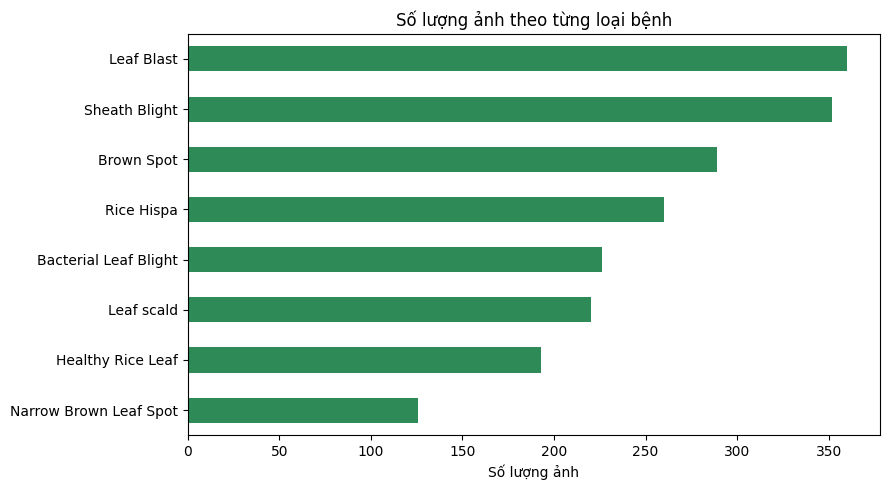

In [5]:
pd.Series(class_counts).sort_values().plot(kind="barh", figsize=(9, 5), color="seagreen")
plt.title("Số lượng ảnh theo từng loại bệnh")
plt.xlabel("Số lượng ảnh")
plt.tight_layout()
plt.show()

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, cls in zip(axes.flatten(), class_names):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    sample_file = os.listdir(cls_dir)[0]
    img = cv2.imread(os.path.join(cls_dir, sample_file))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{cls} ({class_counts[cls]} ảnh)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Tiền xử lý ảnh chống nhiễu

Dùng **CLAHE** (Contrast Limited Adaptive Histogram Equalization) để giảm ảnh hưởng của bóng râm và ánh sáng không đều trước khi trích đặc trưng.

In [7]:
def normalize_lighting(img_bgr):
    """Cân bằng sáng bằng CLAHE để giảm ảnh hưởng của bóng râm/ánh sáng không đều."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

# Xem thử hiệu quả CLAHE trên 1 ảnh mẫu
sample_path = image_paths[0]
sample_img = cv2.imread(sample_path)
sample_normalized = normalize_lighting(sample_img)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(sample_normalized, cv2.COLOR_BGR2RGB)); axes[1].set_title("Sau CLAHE"); axes[1].axis("off")
plt.tight_layout()
plt.show()

## 4. Trích xuất đặc trưng thủ công (Feature Engineering)

Vì Decision Tree/KNN/SVM/Random Forest không tự học đặc trưng từ ảnh thô như CNN, ta cần tự tính ra một **vector đặc trưng cố định** cho mỗi ảnh:

- **Đặc trưng màu sắc (48 + 6 = 54 giá trị):** histogram màu cho 3 kênh H, S, V (không gian màu HSV bền với ánh sáng hơn RGB) + trung bình/độ lệch chuẩn từng kênh
- **Đặc trưng HOG — Histogram of Oriented Gradients:** bắt hình dạng/đường viền của vết bệnh theo hướng cạnh (gradient) - có ích vì mỗi loại bệnh thường có hình dạng vết đặc trưng riêng (đốm tròn, sọc dài, cháy viền...)

Tổng số chiều cụ thể sẽ được in ra khi chạy cell test bên dưới (phụ thuộc tham số HOG).

In [8]:
def extract_features(img_bgr, size=FEATURE_IMG_SIZE):
    """Trích vector đặc trưng màu sắc + hình dạng (HOG) từ 1 ảnh lá lúa."""
    img_bgr = cv2.resize(img_bgr, size)
    img_bgr = normalize_lighting(img_bgr)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    features = []

    # --- Đặc trưng màu: histogram từng kênh H, S, V ---
    for i in range(3):
        hist = cv2.calcHist([img_hsv], [i], None, [16], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)

    # --- Thống kê màu: trung bình + độ lệch chuẩn từng kênh ---
    for i in range(3):
        channel = img_hsv[:, :, i]
        features.append(channel.mean())
        features.append(channel.std())

    # --- Đặc trưng HOG: hình dạng/đường viền vết bệnh theo hướng cạnh ---
    hog_features = hog(gray, orientations=9, pixels_per_cell=(32, 32),
                        cells_per_block=(1, 1), feature_vector=True)
    features.extend(hog_features)

    return np.array(features, dtype=np.float32)

# Kiểm tra thử số chiều vector đặc trưng
test_vector = extract_features(sample_img)
print(f"Số chiều vector đặc trưng: {len(test_vector)}")

Số chiều vector đặc trưng: 198


## 5. Tăng cường dữ liệu train bằng OpenCV (mô phỏng nhiễu)

Tập Test bị nhiễu (che khuất, bóng râm, lệch màu, mờ ống kính). Ta có thể tạo thêm vài phiên bản biến đổi từ mỗi ảnh train bằng OpenCV cơ bản rồi trích đặc trưng từ tất cả các phiên bản đó - giúp model nhìn thấy nhiều biến thể hơn, học tổng quát hơn:

- Lật ảnh, đổi độ sáng (sáng hơn / tối hơn)
- **Xoay ảnh nhẹ** để mô phỏng góc chụp lệch
- **Làm mờ nhẹ** để mô phỏng mờ ống kính

Chỉ áp dụng augmentation cho tập **Train**, không áp dụng cho **Validation/Test** - để đánh giá khách quan, tránh rò rỉ dữ liệu (data leakage).

In [9]:
def make_augmented_versions(img_bgr):
    """Tạo thêm vài phiên bản biến đổi nhẹ từ ảnh gốc, mô phỏng nhiễu trong đề bài."""
    versions = [img_bgr]                                                    # ảnh gốc
    versions.append(cv2.flip(img_bgr, 1))                                   # lật ngang - góc chụp khác
    versions.append(cv2.convertScaleAbs(img_bgr, alpha=1.0, beta=35))       # sáng hơn - mô phỏng nắng gắt
    versions.append(cv2.convertScaleAbs(img_bgr, alpha=1.0, beta=-35))      # tối hơn - mô phỏng bóng râm

    # --- Xoay ảnh nhẹ (Lab 1 - Geometric Transform) ---
    h, w = img_bgr.shape[:2]
    center = (w // 2, h // 2)
    for angle in (-10, 10):                                                 # xoay nhẹ 2 chiều, tránh méo quá nhiều
        rot_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(img_bgr, rot_matrix, (w, h), borderMode=cv2.BORDER_REFLECT)
        versions.append(rotated)

    # --- Làm mờ nhẹ (Lab 2 - Filtering) ---
    versions.append(cv2.GaussianBlur(img_bgr, (5, 5), 0))                  # mờ nhẹ - mô phỏng mờ ống kính/lấy nét kém

    return versions

print("Mỗi ảnh train sẽ được tạo thành 7 phiên bản "
      "(gốc + lật + sáng hơn + tối hơn + xoay ±10° + làm mờ nhẹ).")

Mỗi ảnh train sẽ được tạo thành 7 phiên bản (gốc + lật + sáng hơn + tối hơn + xoay ±10° + làm mờ nhẹ).


## 6. Chia Train/Validation & xây dựng bộ đặc trưng

Chia tập train/validation **trước** khi augmentation, để đảm bảo augmentation chỉ áp dụng cho phần Train.

In [10]:
label2idx = {cls: i for i, cls in enumerate(class_names)}
idx2label = {i: cls for cls, i in label2idx.items()}
print(label2idx)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, image_labels, test_size=VAL_RATIO, stratify=image_labels, random_state=SEED
)
print(f"Train: {len(train_paths)} ảnh | Validation: {len(val_paths)} ảnh")

{'Bacterial Leaf Blight': 0, 'Brown Spot': 1, 'Healthy Rice Leaf': 2, 'Leaf Blast': 3, 'Leaf scald': 4, 'Narrow Brown Leaf Spot': 5, 'Rice Hispa': 6, 'Sheath Blight': 7}
Train: 1722 ảnh | Validation: 304 ảnh


In [11]:
# Trích đặc trưng cho tập TRAIN (có augmentation)
X_train_list, y_train_list = [], []

for path, label in zip(train_paths, train_labels):
    img = cv2.imread(path)
    for version in make_augmented_versions(img):
        X_train_list.append(extract_features(version))
        y_train_list.append(label2idx[label])

X_train = np.array(X_train_list)
y_train = np.array(y_train_list)
print(f"Số mẫu train sau augmentation: {len(X_train)} "
      f"(gốc {len(train_paths)} ảnh x 7 phiên bản)")

Số mẫu train sau augmentation: 12054 (gốc 1722 ảnh x 7 phiên bản)


In [12]:
# Trích đặc trưng cho tập VALIDATION (không augmentation - giữ nguyên ảnh gốc)
X_val_list, y_val_list = [], []

for path, label in zip(val_paths, val_labels):
    img = cv2.imread(path)
    X_val_list.append(extract_features(img))
    y_val_list.append(label2idx[label])

X_val = np.array(X_val_list)
y_val = np.array(y_val_list)
print(f"Số mẫu validation: {len(X_val)}")

Số mẫu validation: 304


In [13]:
# Chuẩn hóa đặc trưng (StandardScaler) - quan trọng cho KNN/SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Đã chuẩn hóa xong đặc trưng (mean=0, std=1).")

Đã chuẩn hóa xong đặc trưng (mean=0, std=1).


## 7. So sánh các thuật toán

Thử lần lượt các thuật toán (Decision Tree, KNN, SVM, Random Forest, Gradient Boosting), đánh giá bằng **Macro F1-Score** trên tập Validation, chọn ra thuật toán tốt nhất.

**Xử lý mất cân bằng lớp:** dùng `class_weight="balanced"` (với các model hỗ trợ) để lớp ít ảnh không bị "lép vế" — phù hợp với cách tính Macro F1.

In [14]:
sample_weight_train = compute_sample_weight("balanced", y_train)

models_dict = {
    "Decision Tree":      DecisionTreeClassifier(max_depth=15, class_weight="balanced", random_state=SEED),
    "KNN":                KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF Kernel)":   SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced", random_state=SEED),
    "Random Forest":      RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting":  GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=SEED),
}

results = {}

for name, clf in models_dict.items():
    if name == "Gradient Boosting":
        # GradientBoostingClassifier không có tham số class_weight, dùng sample_weight thay thế
        clf.fit(X_train_scaled, y_train, sample_weight=sample_weight_train)
    else:
        clf.fit(X_train_scaled, y_train)

    val_preds = clf.predict(X_val_scaled)
    f1 = f1_score(y_val, val_preds, average="macro")
    results[name] = f1
    print(f"{name:20s} | Macro F1 (Validation) = {f1:.4f}")

Decision Tree        | Macro F1 (Validation) = 0.8100
KNN                  | Macro F1 (Validation) = 0.8562
SVM (RBF Kernel)     | Macro F1 (Validation) = 0.9466
Random Forest        | Macro F1 (Validation) = 0.9503
Gradient Boosting    | Macro F1 (Validation) = 0.8866


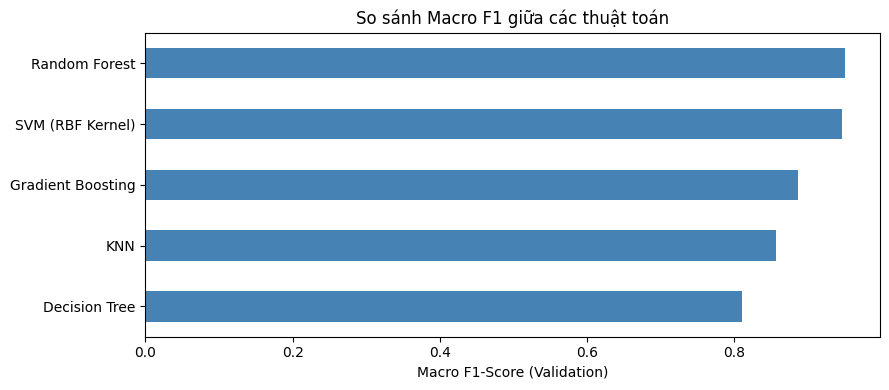


=> Model tốt nhất (đơn lẻ): Random Forest (Macro F1 = 0.9503)


In [15]:
pd.Series(results).sort_values().plot(kind="barh", figsize=(9, 4), color="steelblue")
plt.title("So sánh Macro F1 giữa các thuật toán")
plt.xlabel("Macro F1-Score (Validation)")
plt.tight_layout()
plt.show()

best_model_name = max(results, key=results.get)
best_model = models_dict[best_model_name]
print(f"\n=> Model tốt nhất (đơn lẻ): {best_model_name} (Macro F1 = {results[best_model_name]:.4f})")

## 8. Stacking Ensemble

Thử kết hợp nhiều model lại bằng **Stacking** - các model cơ sở dự đoán trước, rồi 1 model "meta-learner" (Logistic Regression) học cách kết hợp các dự đoán đó lại cho ra kết quả cuối cùng.

In [16]:
estimators = [
    ("rf",  RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1)),
    ("svm", SVC(kernel="rbf", C=10, class_weight="balanced", probability=True, random_state=SEED)),
    ("knn", KNeighborsClassifier(n_neighbors=7)),
]

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1,
)
stacking_model.fit(X_train_scaled, y_train)

stack_preds = stacking_model.predict(X_val_scaled)
stack_f1 = f1_score(y_val, stack_preds, average="macro")
print(f"Stacking Ensemble | Macro F1 (Validation) = {stack_f1:.4f}")

Stacking Ensemble | Macro F1 (Validation) = 0.9568


In [17]:
# Chọn model CUỐI CÙNG: so sánh model đơn lẻ tốt nhất với Stacking
if stack_f1 > results[best_model_name]:
    final_model = stacking_model
    final_model_name = "Stacking Ensemble"
    final_f1 = stack_f1
else:
    final_model = best_model
    final_model_name = best_model_name
    final_f1 = results[best_model_name]

print(f"=> MODEL CUỐI CÙNG ĐƯỢC CHỌN: {final_model_name} (Macro F1 = {final_f1:.4f})")

=> MODEL CUỐI CÙNG ĐƯỢC CHỌN: Stacking Ensemble (Macro F1 = 0.9568)


## 9. Đánh giá chi tiết model cuối cùng trên Validation

In [18]:
final_val_preds = final_model.predict(X_val_scaled)
print(classification_report(y_val, final_val_preds, target_names=class_names, digits=3))

                        precision    recall  f1-score   support

 Bacterial Leaf Blight      1.000     0.971     0.985        34
            Brown Spot      0.932     0.953     0.943        43
     Healthy Rice Leaf      0.964     0.931     0.947        29
            Leaf Blast      0.981     0.981     0.981        54
            Leaf scald      0.941     0.970     0.955        33
Narrow Brown Leaf Spot      0.941     0.842     0.889        19
            Rice Hispa      0.929     1.000     0.963        39
         Sheath Blight      1.000     0.981     0.990        53

              accuracy                          0.964       304
             macro avg      0.961     0.954     0.957       304
          weighted avg      0.964     0.964     0.964       304



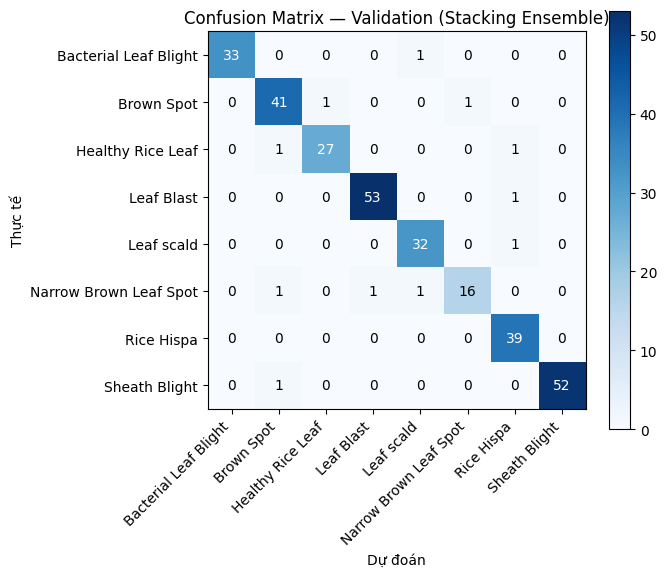

In [19]:
cm = confusion_matrix(y_val, final_val_preds)
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max()/2 else "black")
plt.title(f"Confusion Matrix — Validation ({final_model_name})")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế")
plt.tight_layout()
plt.show()

# 10. Dự đoán trên tập Test & xuất submission.csv

Trích đặc trưng cho ảnh test, rồi dùng model cuối cùng để dự đoán.

In [20]:
test_files = sorted([f for f in os.listdir(TEST_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
test_paths = [os.path.join(TEST_DIR, f) for f in test_files]
print(f"Số lượng ảnh test: {len(test_paths)}")

X_test_list = []
for path in test_paths:
    img = cv2.imread(path)
    X_test_list.append(extract_features(img))

X_test = np.array(X_test_list)
X_test_scaled = scaler.transform(X_test)

final_preds = final_model.predict(X_test_scaled)
print("Đã dự đoán xong cho toàn bộ tập test.")

Số lượng ảnh test: 300
Đã dự đoán xong cho toàn bộ tập test.


In [21]:
submission = pd.DataFrame({
    "image_id": test_files,
    "label": final_preds
})

# Kiểm tra định dạng theo đúng mô tả trong đề PDF (mục 2): 2 cột image_id, label (0-7)
assert list(submission.columns) == ["image_id", "label"], "Sai tên cột!"
assert submission["label"].between(0, 7).all(), "Có nhãn ngoài phạm vi 0-7!"
assert len(submission) == len(test_files), "Số dòng không khớp với số ảnh test!"

submission.to_csv("submission.csv", index=False)
print("Đã lưu submission.csv thành công.")
submission.head(10)

Đã lưu submission.csv thành công.


,image_id,label
0,public_0001.jpg,6
1,public_0002.jpg,7
2,public_0003.jpg,3
3,public_0004.jpg,2
4,public_0005.jpg,7
5,public_0006.jpg,7
6,public_0007.jpg,6
7,public_0008.jpg,6
8,public_0009.jpg,3
9,public_0010.jpg,7


In [22]:
# Kiểm tra nhanh: model có đoán lệch hẳn về 1-2 lớp không (dấu hiệu bug)
pd.Series(final_preds).map(idx2label).value_counts()

Sheath Blight             65
Leaf Blast                53
Brown Spot                45
Bacterial Leaf Blight     39
Rice Hispa                34
Leaf scald                28
Healthy Rice Leaf         23
Narrow Brown Leaf Spot    13
Name: count, dtype: int64